# Notebook 20: The Delayed-Choice Quantum Eraser as an Indivisible Process

**The question.** In Kim et al.'s eraser the idler holds a perfect record of the path at t1 and never interacts
with the signal photon again, so by Paper 1 §3.7 t1 is a division event for the signal photon. The pair does not
divide then, consistent with Barandes: the record sits inside the pair, and Paper 1 §3.9 (eq. 65) has a composite
divide through "interactions between one of the subsystems and the larger environment". The sharp case is later,
at t2: detector D0, a genuine outside environment, records the signal's position x, but x does not fix the idler's
path. If the pair divided at t2, the fringes Kim et al. measure in the D1-sorted data would vanish (§6: visibility
1 → 0). So does eq. 65 require the environment's record to fix the *composite's* configuration, making a
subsystem's record enough only when the partner's configuration is a function of it?

**Goal:** Put Kim et al.'s delayed-choice quantum eraser on the same footing as the double slit of
notebook 05, as one stochastic process whose configurations are photon positions and detector clicks.
Then ask what indivisibility says about "erasure", about the delay, and about division events.
This is a translation and a new application of ISP, not new physics; the prior work is credited section by section.

By the end of this notebook you will be able to:
- Reproduce Kim et al.'s four joint-detection patterns R01–R04 from one joint table P(x, d)
- Read "sorting by the idler detector" as conditioning, and measure each sorted sub-ensemble's divisibility defect
- See that the unsorted screen composes through the path while two of the four sorted sub-ensembles do not
- State the predictability–visibility relation detector by detector (Englert & Bergou), as a trade-off between path record and indivisibility
- Show that Barandes's division-event criterion (Paper 1 §3.7) says t1 divides photon 1, while a persistent-record test on the pair says t1 does not divide the pair
- Answer the run-by-run version of the division-event question
- Show why the 8 ns delay does no work, and what the eraser says about objective division events

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

The experiment: Y.-H. Kim, R. Yu, S. P. Kulik, Y. H. Shih and M. O. Scully, "A Delayed Choice Quantum Eraser",
arXiv:quant-ph/9903047, *Phys. Rev. Lett.* 84, 1 (2000), after Scully and Drühl, *Phys. Rev. A* 25, 2208 (1982).
Other works are cited by author and arXiv number or journal. Section numbers for Paper 1 follow the published
version (§3.5 Interference, §3.7 Division events, §3.9 Entanglement).

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.eraser import (
    DETECTORS,
    conditional_defect,
    kim_model,
    path_predictability,
    sorted_visibility,
)

## 1. The Experiment as Configurations

A pump beam hits a crystal in two regions, A and B (the "slits"). A pair of photons is born in one of them.
The signal photon goes a short way to detector D0, which scans the far-field pattern. The idler goes a long way
(about 2.5 m more, so at least 8 ns later) through a maze of beamsplitters:

- transmitted at BS_A or BS_B → D3 (came from A) or D4 (came from B): **which-path** detectors;
- reflected → a final 50/50 beamsplitter BS → D1 or D2: the path is **erased**.

A coincidence counter pairs each D0 click with the idler click of the same pair; R0j is the D0 pattern sorted by
detector Dj.

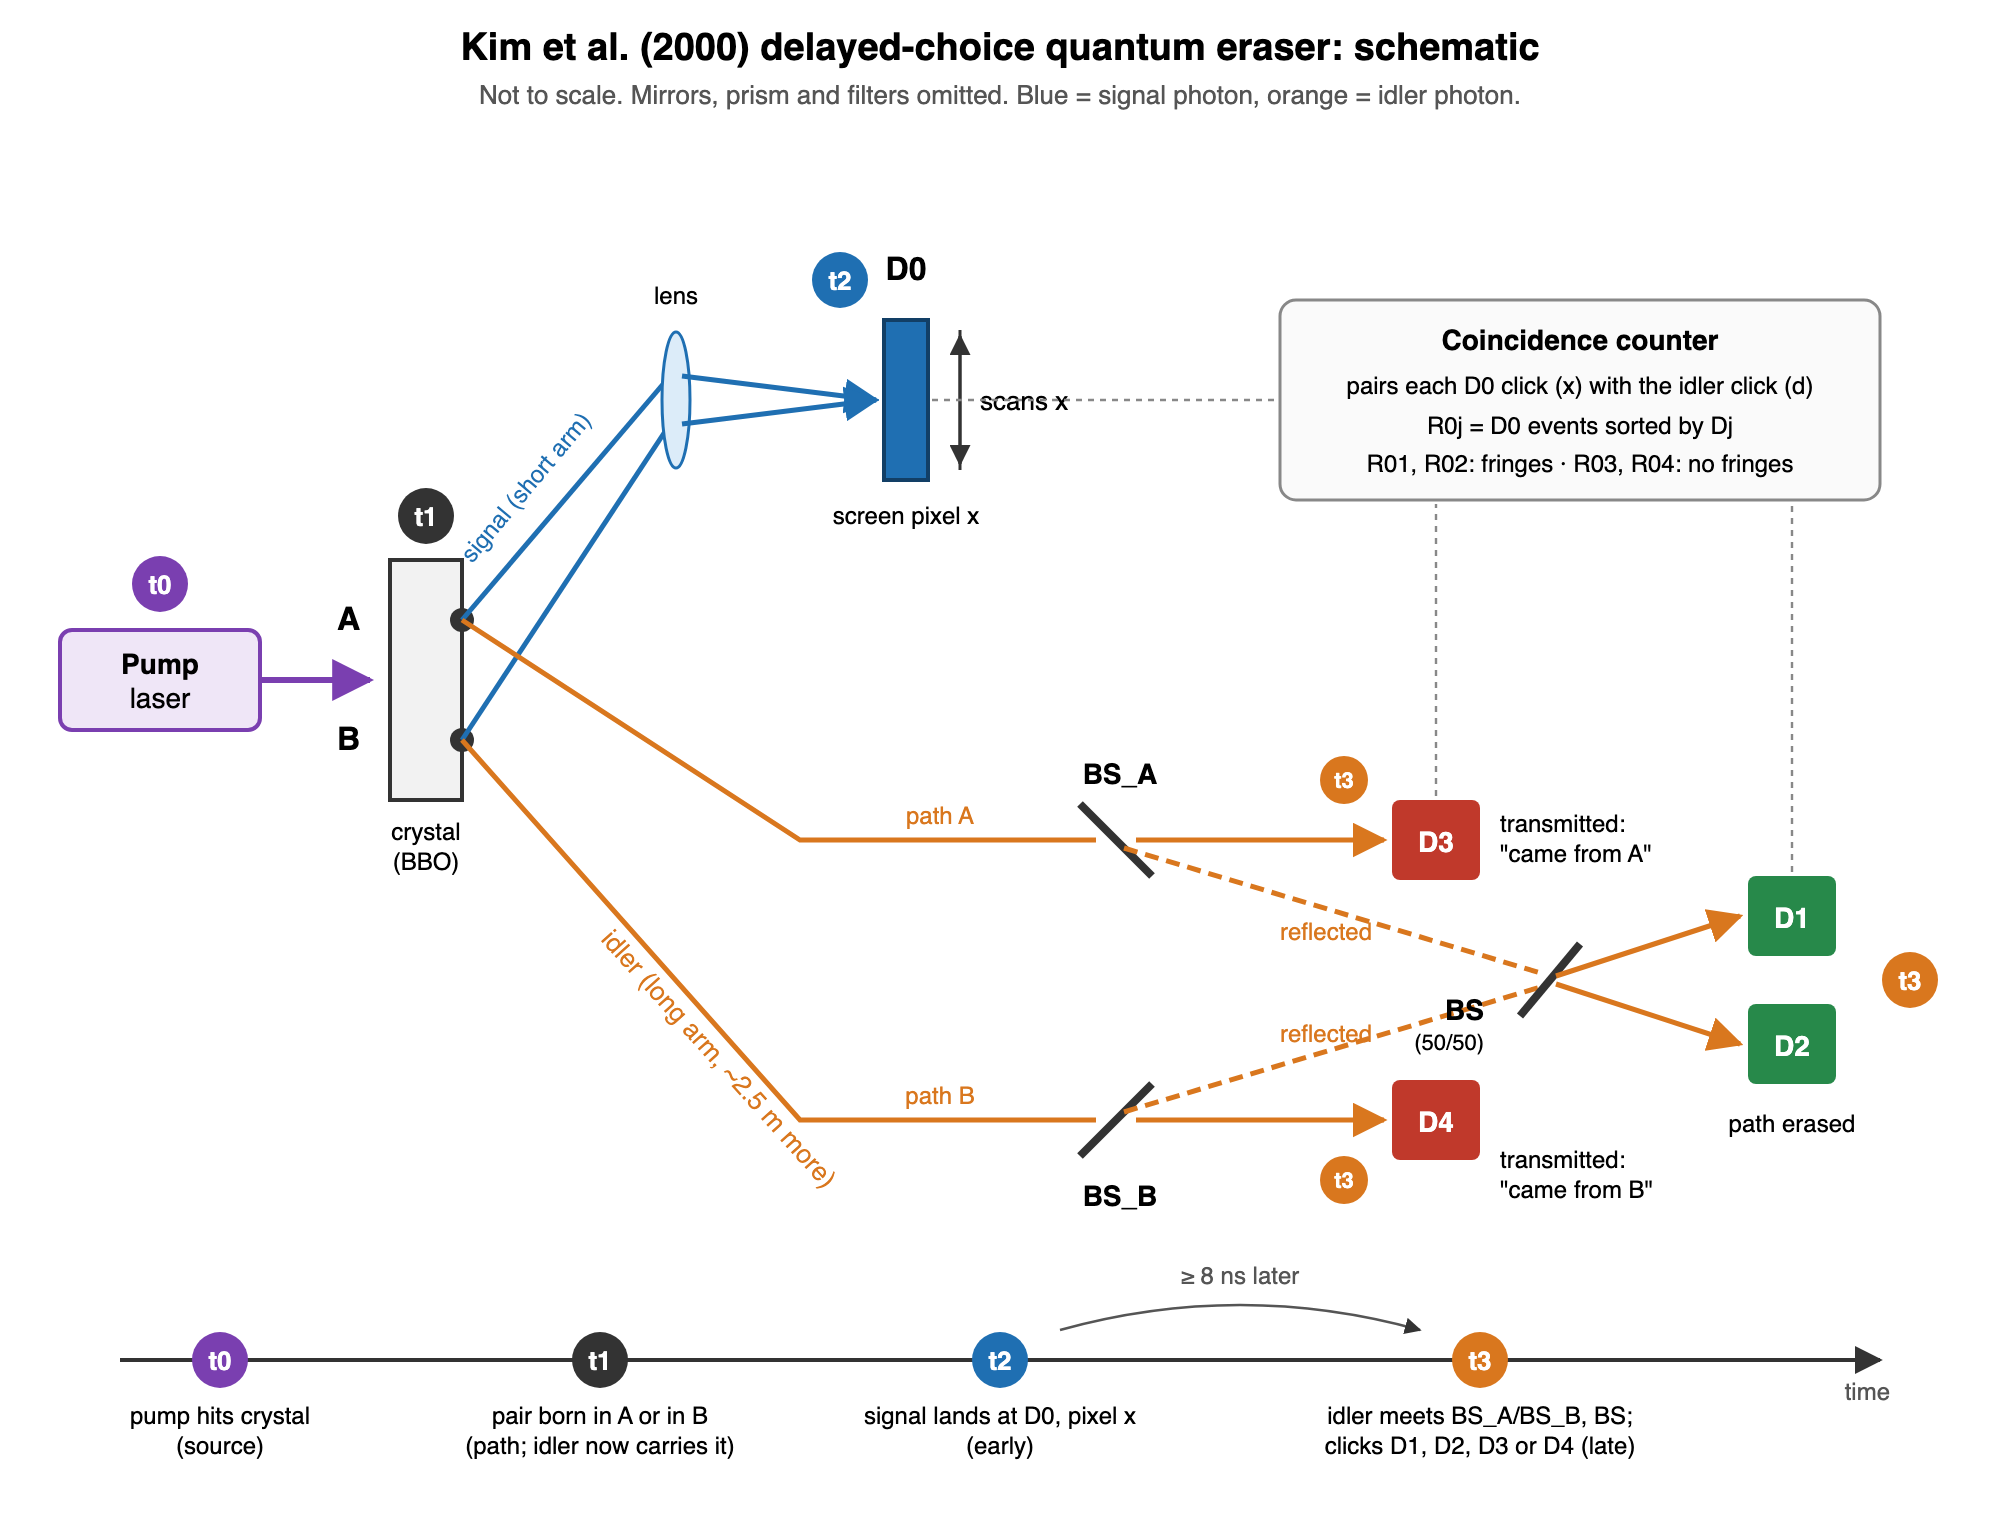

*Figure: Kim et al.'s setup, schematic and not to scale (mirrors, prism and filters omitted). Blue is the signal
photon, orange the idler. The badges mark the four times used throughout this notebook.*

The configurations, in time order:

    t0  source
    t1  path        signal and idler both in A, or both in B
    t2  signal at D0 pixel x                     (early)
    t3  idler at D1, D2, D3 or D4                (late)

On Barandes's reading (Paper 1, §3.5), the pair really is born in A or in B on every run, and the signal
really lands at one pixel. The model's only inputs are the signal arm (the far-field DFT of notebook 05) and a
4×2 idler isometry V (see `isp/eraser.py`). The joint table is P(x, d) = |ψ(x, d)|², with
ψ(x, d) = (1/√2) Σ_s U2[x, s] V[d, s].

In [2]:
n = 24
m = kim_model(n_modes=n, slit_a=10, slit_b=13, r=0.5, theta=np.pi / 4)

print('joint table P(x, d) sums to', round(m['P_joint'].sum(), 15))
print('detector rates P(d):', dict(zip(DETECTORS, np.round(m['P_detector'], 6))))
print('idler isometry columns orthonormal:',
      np.allclose(m['V'].conj().T @ m['V'], np.eye(2)))

joint table P(x, d) sums to 1.0
detector rates P(d): {'D1': np.float64(0.25), 'D2': np.float64(0.25), 'D3': np.float64(0.25), 'D4': np.float64(0.25)}
idler isometry columns orthonormal: True


## 2. Kim et al.'s Four Patterns, and the Flat Screen

Kim et al. report R01 and R02 with fringes shifted by π, and R03, R04 without fringes (their Figs. 3–5).
The D0 singles, which never look at the idler, are predicted to show no fringes at all (Kim et al. do not report
them separately; R01 + R02 has no fringe).

Model limitation: the slits here are points on a pixel grid, so there is no single-slit (sinc²) envelope. The D0
singles and R03/R04 come out flat, whereas Kim et al.'s data sit under the sinc² envelope of the finite slit
width (their expressions for R01 and R02). Only the fringe structure is modelled.

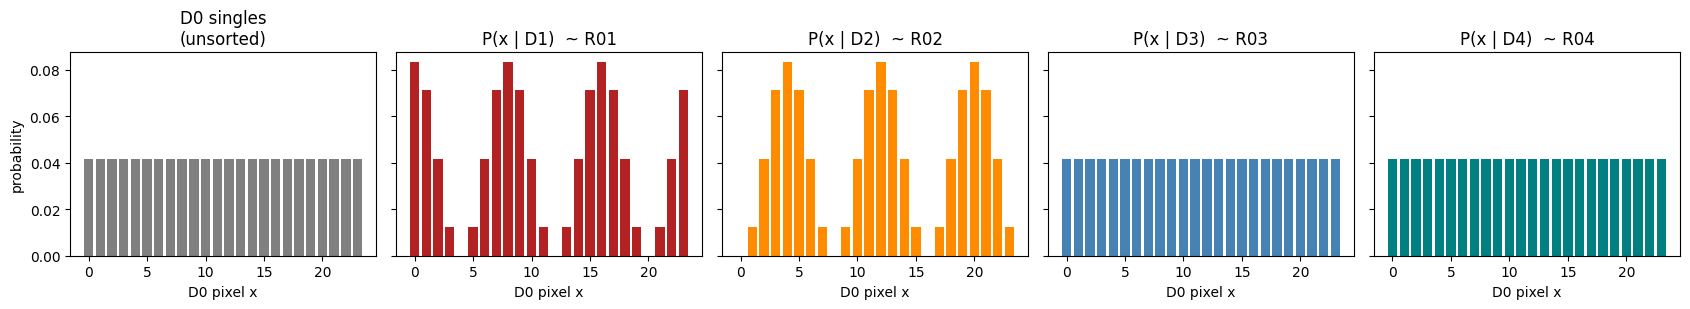

D0 singles flat at 1/n: True
R01 + R02 (weighted) = flat: True


In [3]:
k = np.arange(n)
Pxd = m['P_x_given_d']

fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
axes[0].bar(k, m['P_screen'], color='gray')
axes[0].set_title('D0 singles\n(unsorted)')
colors = ['firebrick', 'darkorange', 'steelblue', 'teal']
for d in range(4):
    axes[d + 1].bar(k, Pxd[:, d], color=colors[d])
    axes[d + 1].set_title(f'P(x | {DETECTORS[d]})  ~ R0{d + 1}')
for ax in axes:
    ax.set_xlabel('D0 pixel x')
axes[0].set_ylabel('probability')
plt.tight_layout()
plt.show()

print(f'D0 singles flat at 1/n: {np.allclose(m["P_screen"], 1 / n)}')
print(f'R01 + R02 (weighted) = flat: {np.allclose(Pxd[:, :2] @ m["P_detector"][:2] / m["P_detector"][:2].sum(), 1 / n)}')

## 3. Sorting Is Conditioning: the Divisibility Defect of Each Sub-Ensemble

Notebook 05 showed that the fringe is the divisibility defect through the slit plane (Barandes's eq. 43, Paper 1 §3.5).
Do the same here, once per idler detector:

    Δ(x | d) = P(x | d) − Σ_s P(x | s) P(s | d)

Δ = 0 means the d-sorted pattern is what you get by fixing the path at t1 and propagating it, a mixture of the
two single-path patterns. Δ ≠ 0 means it is not.

In [4]:
D = conditional_defect(m)
for d in range(4):
    print(f'{DETECTORS[d]}:  max |defect| = {np.abs(D[:, d]).max():.3e}')
print()
print('weighted over detectors, sum_d P(d) * defect(x | d):',
      f'{np.abs(D @ m["P_detector"]).max():.1e}')

D1:  max |defect| = 4.167e-02
D2:  max |defect| = 4.167e-02
D3:  max |defect| = 2.776e-17
D4:  max |defect| = 2.776e-17

weighted over detectors, sum_d P(d) * defect(x | d): 1.7e-17


**Reading.**
- The D3/D4 sub-ensembles compose through the path: their idler click is a path record, and conditioning on it
  conditions on the configuration at t1.
- The D1/D2 sub-ensembles do not: each is a fringe, and the fringe *is* its defect, exactly as in notebook 05.
- Averaged over detectors the defects cancel, so the unsorted screen composes through the path. Whether t1 is a
  division event depends on whose process is asked about, photon 1's or the pair's; Section 4 compares the two.
- Nothing about photon 1 changes when the idler clicks. The four patterns are four sub-tables of one table.
  Sorting picks out sub-ensembles of runs. It does not change the past.

Prior work: the qualitative story (definite path, sorted fringes, no retrocausality) is not new. Catani, Leifer,
Schmid & Spekkens (*Quantum* 7, 1119, 2023; arXiv:2111.13727) reproduce the eraser in a classical, epistemically
restricted toy theory; Griffiths (quant-ph/9810016) and Hiley & Callaghan (arXiv:1602.06100) give no-retrocausality
readings of delayed choice. The sorted defect itself is Barandes's eq. 43 cross term inside one sub-ensemble, i.e.
Englert & Bergou's sorted interference term (Section 5); calling it a divisibility defect is a relabelling.

## 4. Was There a Division Event at t1?

The entanglement at t1 writes the path into the idler. For the D3/D4 runs that record survives; for the D1/D2 runs
it is erased. To ask whether the *pair* divides at t1 we use a working test from an earlier lab study, the
**persistent-record test**: t1 is a division event of the joint process to accuracy ε only if the
*persistent-record bound* stays below ε at **every** later time:

    bound(t) = 2 Σ_z |b(z, A)| |b(z, B)|

where b(z, s) is the history amplitude from the source through path s at t1 to the joint configuration z at time t.
The actual defect, Σ_z |P(z) − P_divided(z)|, is what you lose by restarting the process from the path at t1.
Caveat: the bound needs the joint transitions re-rooted at t1, which Γ(· ← 0) alone does not supply, so it is not
a Γ-only criterion; this model supplies them. Its second step is the triangle inequality for history vectors. It is
used here as a working definition, not as a result.

**The bound is an Englert–Bergou quantity.** Englert & Bergou (*Opt. Commun.* 179, 337 (2000)) sort the photons by
the outcome k of a measurement on the path's "environment" (here: the idler detector d) and define the
*quantum-erasure visibility* V^QE = Σ_k p_k V_k, the outcome-weighted visibility of the sorted fringes (their eq. 30).
From positivity they bound it by 2 Σ_k a_k b_k with a_k b_k = √(P(k, A) P(k, B)) (their eqs. 75–76). The bound
above is that right-hand side, with the screen position x counted as part of the record: for a far-field screen
(equal moduli over x, as here) the two coincide; in general ours is ≤ theirs by Cauchy–Schwarz. For a pure record
it also equals V^QE itself, which the code below checks.

Kim et al. (r = 1/2, theta = pi/4)
  t2 (D0 fired, idler still in its arm):  bound = 0.000   defect = 0.000
  t3 (idler at D1..D4):                   bound = 0.500   defect = 0.302
  signal photon alone, defect at t2, t3:  0.0e+00, 6.2e-17

joint defect at t3 = sum_d P(d) * L1 sorted defect (Section 3): 0.301777 vs 0.301777
Englert-Bergou V^QE = sum_d P(d) V_d = 0.500000  vs  persistent-record bound at t3 = 0.500000


max |bound_t3 - r |sin 2 theta|| over the grid: 4.4e-16


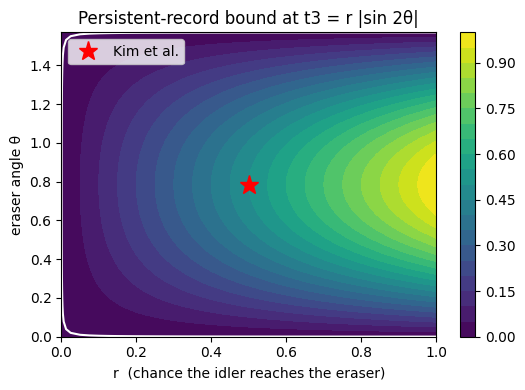

In [5]:
from isp.eraser import path_record_check

c = path_record_check(n_modes=n, slit_a=10, slit_b=13, r=0.5, theta=np.pi / 4)
print('Kim et al. (r = 1/2, theta = pi/4)')
print(f'  t2 (D0 fired, idler still in its arm):  bound = {c["bound_t2"]:.3f}   defect = {c["defect_t2"]:.3f}')
print(f'  t3 (idler at D1..D4):                   bound = {c["bound_t3"]:.3f}   defect = {c["defect_t3"]:.3f}')
print(f'  signal photon alone, defect at t2, t3:  {c["signal_marginal_defect_t2"]:.1e}, {c["signal_marginal_defect_t3"]:.1e}')
print()
weighted = (np.abs(conditional_defect(m)).sum(axis=0) * m['P_detector']).sum()
print(f'joint defect at t3 = sum_d P(d) * L1 sorted defect (Section 3): {c["defect_t3"]:.6f} vs {weighted:.6f}')
VQE = (m['P_detector'] * sorted_visibility(m)).sum()
print(f'Englert-Bergou V^QE = sum_d P(d) V_d = {VQE:.6f}  vs  persistent-record bound at t3 = {c["bound_t3"]:.6f}')

rs = np.linspace(0, 1, 41)
ths = np.linspace(0, np.pi / 2, 41)
B = np.array([[path_record_check(n_modes=n, r=r, theta=th)['bound_t3'] for r in rs] for th in ths])
print(f'max |bound_t3 - r |sin 2 theta|| over the grid: {np.abs(B - np.outer(np.abs(np.sin(2 * ths)), rs)).max():.1e}')

fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.contourf(rs, ths, B, levels=20, cmap='viridis')
ax.contour(rs, ths, B, levels=[1e-3], colors='white')
ax.plot(0.5, np.pi / 4, 'r*', ms=14, label='Kim et al.')
ax.set_xlabel('r  (chance the idler reaches the eraser)')
ax.set_ylabel('eraser angle θ')
ax.set_title('Persistent-record bound at t3 = r |sin 2θ|')
fig.colorbar(im); ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

**Results.**
- **The pair does not divide at t1 on Kim's setup.** The bound is 0 at t2 and r|sin 2θ| = 0.5 at t3, and the actual
  defect is 0.30. By the persistent-record test, applied to the joint configuration of both photons, t1 is not a
  division event for the pair. The test fires only on the edges of the plot (r = 0: no eraser; θ = 0 or π/2: the
  "eraser" is another which-path measurement).
- **Barandes's own criterion says t1 *is* a division event for photon 1.** Paper 1 §3.7 (eqs. 45–56) derives a
  division event for a subject system from two conditions: at t′ its environment holds a perfect record of the
  system's configuration, and afterwards the two evolve without interacting. Take photon 1 as the subject and the
  idler as its environment: both conditions hold at t1, and photon 1's own Γ divides there (signal-marginal defect 0
  at t2 and t3, printed above).
- **So photon 1 divides at t1 and the pair does not, and the erasure lives in the gap.** Sorting photon 1 by the
  idler's later click is a statement about the joint process, which did not divide at t1. This agrees with Paper 1
  §3.9 (eqs. 63–66), where a composite divides at a later time "perhaps due to interactions between one of the
  subsystems and the larger environment, as spelled out in Subsection 3.7" (just before eq. 65): at t1 the only
  record is the idler, inside the pair, so nothing outside the pair has recorded anything. The open case is t2
  (Section 6).
- **The two defects are one defect.** The joint defect at t3 is exactly the detector-weighted sum of the sorted
  defects of Section 3, so "erasure brings the fringes back" and "t1 was not a division event for the pair" are the
  same number.
- **The test's verdict on t1 is settled only after t2.** At t2 the bound is 0: everything that has happened so far
  is consistent with a division at t1. Whether t1 *was* a division event of the pair is fixed by what the idler
  meets later. If θ is chosen after D0 fires (delayed choice proper, as in Ma et al., *PNAS* 110, 1221 (2013),
  arXiv:1206.6578), the verdict on t1 depends on a later choice. No configuration and no statistic of photon 1
  changes, so this is not retrocausation; but it means that under this test "division event of the pair" is not a
  fact local in time. It is also why a *causal* reset of the pair at the first perfect record is falsified by
  erasers (Section 7) while the retrospective test agrees with quantum mechanics.

**Prior work.** The number r|sin 2θ| is Englert & Bergou's quantum-erasure visibility of Kim's sorting (see above);
for this far-field model the persistent-record bound equals the right-hand side of their eq. (76). What is ours is reading it as the ISP division-event test for t1.
The divisibility structure of interferometers is studied in two papers that are closely related,
the same physics in different language, though neither treats the quantum eraser (beyond a passing mention):
- Siltanen, Kuusela & Piilo, "Interferometric Approach to Open Quantum Systems and Non-Markovian Dynamics"
  (arXiv:2008.02826): path-wise dephasing inside an interferometer is Markovian "while the joint dynamics displays
  non-Markovian features", and measuring the path can create or destroy memory effects. This is the open-systems
  counterpart of this section's "marginal composes, joint process not divided".
- Kam & Wong, "Conditioning on the Future: A Filtration-Theoretic Formalization of Wheeler's Participatory Universe"
  (arXiv:2609.19025): classical conditioning (Doob h-transforms, Markov bridges) for Wheeler's delayed choice and a
  Mach–Zehnder with and without a which-path monitor; they cite Barandes but call their aim orthogonal to his.

What we did not find in these papers, in Englert & Bergou, or in two literature passes is a published ISP treatment
of the quantum eraser: Barandes's §3.7 criterion and a persistent-record test on the pair applied to Kim et al.'s
setup and found to disagree, with the pair's verdict on t1 settled only after t2. The qualitative idea that erasing the record undoes the
division event does circulate informally in online discussion of Barandes's framework (not peer-reviewed). This
is a new application of ISP, not new physics.

### 4b. Run by run: is t1 a division event on the D3 runs?

Restrict the persistent-record test to the runs that end at one idler detector d: sum the bound and the defect only over later
configurations z = (x, d) with that d, and divide by P(d).

In [6]:
from isp.eraser import per_run_record_check

for r_, th_ in ((0.5, np.pi / 4), (0.4, 0.3)):
    p = per_run_record_check(n_modes=n, r=r_, theta=th_)
    print(f'r = {r_}, theta = {th_:.3f}   (|sin 2 theta| = {abs(np.sin(2 * th_)):.4f})')
    for d in range(4):
        print(f'  {DETECTORS[d]}:  P(d) = {p["P_d"][d]:.3f}   bound/P(d) = {p["bound_given_d"][d]:.4f}'
              f'   defect/P(d) = {p["defect_given_d"][d]:.4f}')
    print(f'  sum_d bound_d = {p["bound_d"].sum():.4f}  (= whole-ensemble bound r|sin 2 theta| = {r_ * abs(np.sin(2 * th_)):.4f})')
    print()

r = 0.5, theta = 0.785   (|sin 2 theta| = 1.0000)
  D1:  P(d) = 0.250   bound/P(d) = 1.0000   defect/P(d) = 0.6036
  D2:  P(d) = 0.250   bound/P(d) = 1.0000   defect/P(d) = 0.6036
  D3:  P(d) = 0.250   bound/P(d) = 0.0000   defect/P(d) = 0.0000
  D4:  P(d) = 0.250   bound/P(d) = 0.0000   defect/P(d) = 0.0000
  sum_d bound_d = 0.5000  (= whole-ensemble bound r|sin 2 theta| = 0.5000)

r = 0.4, theta = 0.300   (|sin 2 theta| = 0.5646)
  D1:  P(d) = 0.200   bound/P(d) = 0.5646   defect/P(d) = 0.3408
  D2:  P(d) = 0.200   bound/P(d) = 0.5646   defect/P(d) = 0.3408
  D3:  P(d) = 0.300   bound/P(d) = 0.0000   defect/P(d) = 0.0000
  D4:  P(d) = 0.300   bound/P(d) = 0.0000   defect/P(d) = 0.0000
  sum_d bound_d = 0.2259  (= whole-ensemble bound r|sin 2 theta| = 0.2259)



**Results.**
- Restricted to the D3/D4 runs, the bound and defect are exactly 0. On the D1/D2 runs the bound per run is
  |sin 2θ| (1 for Kim's setup) and the defect per run is the sorted defect of Section 3.
- The whole-ensemble bound is the P(d)-weighted average of the per-run bounds. In post-selected terms, Kim's 0.5
  is "half the runs look divided at t1, half maximally not".
- So the run-by-run question has a clean answer, but it is a *post-selected* answer: which kind of run this is
  becomes known only at t3. A reset theory that divides at t1 exactly on the runs that will end at D3/D4 predicts
  the same table (dividing those runs changes nothing, since their defect is 0), so it is empirically equivalent and
  as future-dependent as the test itself.
- Barandes defines division events for the process, not for sub-ensembles picked out by later outcomes, so "t1 was
  a division event on the D3/D4 runs" is not an ISP statement. It is consistent-histories language: the per-run
  statement is the counterpart of consistent-histories reasoning (the path family is consistent together with the
  D3/D4 outcomes and not with D1/D2; Griffiths, quant-ph/9810016, treats Wheeler's delayed choice this way). Likely
  known in substance in that language; not lit-checked for the eraser.

## 5. Predictability and Visibility, Detector by Detector

Replace the 50/50 eraser with a beamsplitter at angle θ (θ = π/4 is Kim's; θ = 0 makes D1 and D2 which-path too).
For each detector d, the path predictability 𝒫_d = |P(A | d) − P(B | d)| of the d-sorted sub-ensemble and the
visibility V_d of its fringe satisfy 𝒫_d² + V_d² ≤ 1 (Englert & Bergou 2000, eq. 78), with equality for a pure
record (their eqs. 7 and 11 applied to the sub-ensemble). The unsorted form P² + V² ≤ 1 (their eq. 36) is due to
Greenberger & Yasin and to Jaeger, Shimony & Vaidman, with an entropic precursor in Wootters & Zurek.

Terminology, following Englert & Bergou: 𝒫_d is a *predictability* of one sub-ensemble, not Englert's
*distinguishability* D, which is the best which-path knowledge over all ways of reading the idler (their eq. 26);
Englert's duality V² + D² ≤ 1 (*PRL* 77, 2154 (1996)) concerns the unsorted visibility. Kim's own sorting has
which-path knowledge K = Σ_d P(d) 𝒫_d = (1 − r) + r|cos 2θ| and erasure visibility V^QE = r|sin 2θ| (Section 4);
K² + (V^QE)² = 0.5 for Kim, so it is neither a which-path sorting nor an erasure sorting but half of each.

max |Pred^2 + V^2 - 1| over theta, detector D1: 8.9e-16
L1 defect / visibility, D1, where V > 0.05: 0.603553 .. 0.603553


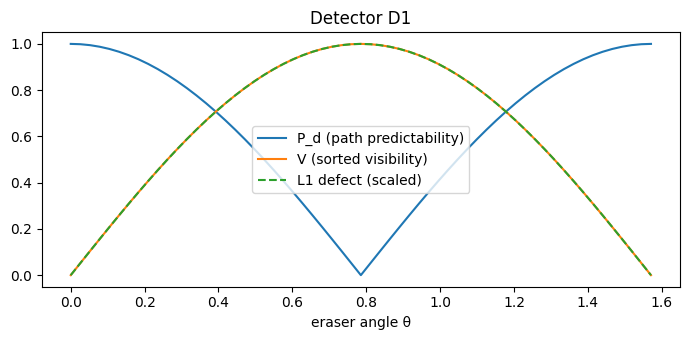

In [7]:
thetas = np.linspace(0, np.pi / 2, 61)
Dd1, Vd1, def1 = [], [], []
for th in thetas:
    mm = kim_model(n_modes=n, r=0.5, theta=th)
    Dd1.append(path_predictability(mm)[0])
    Vd1.append(sorted_visibility(mm)[0])
    def1.append(np.abs(conditional_defect(mm)[:, 0]).sum())
Dd1, Vd1, def1 = map(np.array, (Dd1, Vd1, def1))

print(f'max |Pred^2 + V^2 - 1| over theta, detector D1: {np.abs(Dd1**2 + Vd1**2 - 1).max():.1e}')
ok = Vd1 > 0.05
ratio = def1[ok] / Vd1[ok]
print(f'L1 defect / visibility, D1, where V > 0.05: {ratio.min():.6f} .. {ratio.max():.6f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thetas, Dd1, label='P_d (path predictability)')
ax.plot(thetas, Vd1, label='V (sorted visibility)')
ax.plot(thetas, def1 / def1.max(), '--', label='L1 defect (scaled)')
ax.set_xlabel('eraser angle θ'); ax.set_title('Detector D1'); ax.legend()
plt.tight_layout(); plt.show()

**Pure records.** The d-sorted defect is the cross term of the two path amplitudes (Barandes's eq. 43, one
sub-ensemble at a time). Its single Fourier amplitude is V_d/2; the L1 ratio printed above is a fixed property of
the fringe shape on this pixel grid (2/π ≈ 0.637 in the continuum; 0.6036 for this slit pair, the only one
computed here). So
"𝒫_d² + V_d² = 1" reads as "path record² + (scaled defect)² = 1": a restatement.

**Caveat on P(s | d).** The comparison Σ_s P(x | s) P(s | d) uses the joint probability of the path at t1 and the
detector at t3. ISP assigns joint probabilities only between the conditioning time 0 and one later time; joint
probabilities at two later times are left unspecified (Paper 1 §2.2). So P(s | d) is the would-be
division's prediction, the right comparison for eq. 43, not a claim about what happened at t1 on the D1 runs.

### 5b. Imperfect records

Now let the path leave a marker |m_s⟩ in the idler that need not be orthogonal (|⟨m_A|m_B⟩| > 0), plus a copy
|e_s⟩ in an environment nobody measures, with unbalanced arms (P(A) ≠ 1/2), and read the idler in any basis W
(`marker_model` in `isp/eraser.py`).

In [8]:
from isp.eraser import marker_model, fringe_visibility_exact

rng = np.random.default_rng(5)
def pair(ov):
    Q, _ = np.linalg.qr(rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)))
    return Q @ np.array([1, 0], complex), Q @ np.array([ov, np.sqrt(1 - abs(ov) ** 2)], complex)
def haar2():
    Q, R = np.linalg.qr(rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)))
    return Q * (np.diag(R) / np.abs(np.diag(R)))

worst_identity, worst_bound, S = 0.0, 0.0, []
for _ in range(500):
    pA = rng.uniform(0.05, 0.95)
    mA, mB = pair(rng.uniform(0, 1) * np.exp(1j * rng.uniform(0, 2 * np.pi)))
    eA, eB = pair(rng.uniform(0, 1) * np.exp(1j * rng.uniform(0, 2 * np.pi)))
    mm = marker_model(pA, mA, mB, eA, eB, haar2(), n_modes=n)
    okd = mm['P_detector'] > 1e-9
    Psd = mm['P_s_given_d'][:, okd]
    Dd = np.abs(Psd[0] - Psd[1])
    Vd = fringe_visibility_exact(mm['P_x_given_d'][:, okd])
    gap = 1 - Dd**2 - Vd**2
    worst_identity = max(worst_identity, np.abs(gap - 4 * Psd[0] * Psd[1] * (1 - mm['kappa'][okd]**2)).max())
    Delta = mm['P_x_given_d'][:, okd] - mm['P_x_given_s'] @ Psd
    Pxs = mm['P_x_given_s']
    bnd = 2 * np.sqrt(np.outer(Pxs[:, 0] * Pxs[:, 1], Psd[0] * Psd[1]))
    worst_bound = max(worst_bound, (np.abs(Delta) / (bnd + 1e-300)).max())
    S.extend(Dd**2 + Vd**2)

print('500 random imperfect records, every detector that fires:')
print(f'  max Pred_d^2 + V_d^2                                = {max(S):.5f}  (<= 1)')
print(f'  max |gap - 4 P(A|d) P(B|d) (1 - kappa_d^2)|         = {worst_identity:.1e}')
print(f'  max |Delta(x|d)| / 2 sqrt(P(x|A)P(x|B)P(A|d)P(B|d)) = {worst_bound:.5f}  (<= 1)')

500 random imperfect records, every detector that fires:
  max Pred_d^2 + V_d^2                                = 1.00000  (<= 1)
  max |gap - 4 P(A|d) P(B|d) (1 - kappa_d^2)|         = 4.4e-15
  max |Delta(x|d)| / 2 sqrt(P(x|A)P(x|B)P(A|d)P(B|d)) = 0.99393  (<= 1)


**What this shows.**
- Per detector, 𝒫_d² + V_d² ≤ 1, and the gap is exactly 4 P(A|d) P(B|d) (1 − κ_d²), where κ_d is the fraction of
  coherence that sorting on d leaves (1 for a pure record). The missing coherence went to the environment. This is
  Englert & Bergou's eqs. (7) and (11) applied to the d-sorted sub-ensemble, with κ_d their |ε_k|.
- **A bound on the sorted defect.** |Δ(x | d)| ≤ 2 √(P(x|A) P(x|B) P(A|d) P(B|d)). This is the x-resolved form of
  Englert & Bergou's positivity bound on the cross term (their eqs. 19 and 75), and nothing in it is specific to
  ISP. It is not a Γ-level statement: P(x | s) and P(A | d) are two-time quantities that Γ(· ← 0) does not supply
  (see the caveat on P(s | d) above).

### 5c. What the realised Γ cannot see

In [9]:
e0, e1 = np.array([1, 0], complex), np.array([0, 1], complex)
W_path = np.eye(2, dtype=complex)
W_erase = np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
erasable = dict(pA=0.5, mA=e0, mB=e1, eA=e0, eB=e0)   # record held by the idler only
locked   = dict(pA=0.5, mA=e0, mB=e1, eA=e0, eB=e1)   # record also copied to the environment

same = np.abs(marker_model(W=W_path, n_modes=n, **erasable)['P_joint']
              - marker_model(W=W_path, n_modes=n, **locked)['P_joint']).max()
print(f'idler read for the path: max difference of the joint tables = {same:.1e}')
for name, rec in (('erasable', erasable), ('locked', locked)):
    V = fringe_visibility_exact(marker_model(W=W_erase, n_modes=n, **rec)['P_x_given_d'])
    print(f'idler read for erasure, {name:8s}: sorted visibilities = {np.round(V, 6)}')

idler read for the path: max difference of the joint tables = 0.0e+00
idler read for erasure, erasable: sorted visibilities = [1. 1.]
idler read for erasure, locked  : sorted visibilities = [0. 0.]


Two records give identical tables when the idler is read for the path, yet one can be fully erased and the other
not at all. Which-path tables come from the main diagonal of the path–record state and fringes from its
off-diagonal, so the first cannot fix the second (Englert & Bergou, Fig. 2; their eqs. 48–50 are the "locked" case:
full which-path knowledge, coherence C = 0). Erasability is a property of the alternative laws (other settings of
W), not of the realised process.
This matters for Section 4: the persistent-record test inspects only the realised process, so "was t1 a division event?" depends on which
law was actually run, not on a counterfactual one.

**Prior work (this section is a translation).** Englert & Bergou, "Quantitative quantum erasure", *Opt. Commun.* 179,
337 (2000), read in the original: sorting by an environment measurement, predictability P, which-path knowledge K,
distinguishability D, quantum-erasure visibility V^QE and coherence C; P ≤ K ≤ D, V ≤ V^QE ≤ C; the erasure relation
P² + C² ≤ 1; K² + (V^QE)² ≤ 1 for every sorting; and 𝒫_k² + V_k² ≤ 1 per sub-ensemble. Before them: Wootters & Zurek,
*Phys. Rev. D* 19, 473 (1979); Greenberger & Yasin, *Phys. Lett. A* 128, 391 (1988); Jaeger, Shimony & Vaidman,
*PRA* 51, 54 (1995); Englert, *PRL* 77, 2154 (1996); Björk & Karlsson, *PRA* 58, 3477 (1998), who introduced K
("measured distinguishability") and V^QE ("conditioned visibility"). Experiment: Dürr & Rempe, *Opt. Commun.* 179,
323 (2000), tested K² + (V^QE)² ≤ 1 and its per-sub-ensemble form. Later: Schwindt, Kwiat & Englert, *PRA* 60,
4285 (1999), including "non-erasing" erasure with fully mixed markers; Jakob & Bergou, *PRA* 66, 062107 (2002),
quant-ph/0206200 (a conditional eraser that violates the unconditional erasure relation), and quant-ph/0302075 (which
ties predictability and visibility to the concurrence); Coles, Kaniewski & Wehner, *Nat. Commun.* 5, 5814 (2014).
The bound on the sorted defect is also the Cauchy–Schwarz inequality |D(α, β)|² ≤ D(α, α) D(β, β) for a positive
decoherence functional in Gell-Mann and Hartle's consistent histories (stated, e.g., in arXiv:quant-ph/9704031).
Catani, Leifer, Scala, Schmid & Spekkens (arXiv:2211.09850, *PRA* 108, 022207 (2023)) show the quantitative duality cannot be reproduced by any
noncontextual model, so this is the part of the eraser a classical toy model cannot reach.

## 6. The Delay Does No Work

In Kim et al. the signal reaches D0 at least 8 ns before the idler reaches its detectors. Swap the order (idler
first) and apply the persistent-record test at the first detection, t2, two ways:
- **divide on the detected photon only** (pixel x if D0 fires first, detector d if the idler fires first);
- **divide on the full joint configuration** (the detected photon *and* the other photon's path).

In [10]:
from isp.eraser import delay_check

c6 = delay_check(n_modes=n, r=0.5, theta=np.pi / 4)
print(f'joint table, D0 first vs idler first: max difference {c6["order_difference"]:.1e}')
print(f'bound at t2, divide on the detected photon only:  D0 first {c6["bound_detected_only_D0_first"]:.3f},'
      f'  idler first {c6["bound_detected_only_idler_first"]:.3f}')
print(f'bound at t2, divide on the full joint configuration: {c6["bound_full_joint"]:.3f}')
print(f'R01 visibility: actual {c6["R01_visibility_actual"]:.3f}; '
      f'if the joint process were divided at t2: {c6["R01_visibility_if_fully_divided_at_t2"]:.1e}')

joint table, D0 first vs idler first: max difference 6.9e-18
bound at t2, divide on the detected photon only:  D0 first 0.000,  idler first 0.000
bound at t2, divide on the full joint configuration: 0.500
R01 visibility: actual 1.000; if the joint process were divided at t2: 1.4e-16


**Results.**
- The joint table is identical in both orders. This holds by construction: both orders build the same amplitude
  (the two detections act on different factors and commute), so the printed difference checks the code, not the
  physics.
- Dividing on the detected photon only gives bound 0, also by construction: the detected photon's own
  configuration is part of every later configuration, so each later configuration has a single class.
- The non-trivial number is the other one. Dividing the full joint configuration at t2 has bound 0.5, and doing it
  would erase R01's fringes (visibility 1 → 0). The other photon's path stays undivided at the first detection.
- So after D0 fires, the correlation between x and the idler's later click is carried by the joint law still rooted
  at t0, the source, not by anything running from t3 back to t2. Which photon is detected first changes with the
  order; no prediction does.
- **This is the open case for eq. 65.** At t2 the signal photon interacts with D0, an environment outside the pair,
  exactly the situation Paper 1 §3.9 describes ("interactions between one of the subsystems and the larger
  environment"). Yet the pair must not divide at t2, or R01's fringes vanish. On our reading, §3.7's derivation needs
  the environment to record the configuration of whatever divides; D0 records x, which fixes the signal's
  configuration but not the idler's path. If that reading is right, eq. 65 applies only when the record fixes the
  composite's configuration, i.e. when the partner's configuration is a function of the recorded one (as for
  perfectly correlated pairs), and an eraser is the case where it is not. Whether that is Barandes's intent is the
  question this notebook puts to him.
- What remains time-asymmetric is only the test's verdict on t1 (Section 4): it is settled when the idler meets
  BS_A/BS_B and BS, whichever photon is detected first.

Prior work: that the order of detections cannot matter is standard (the two photons' detections commute; see e.g.
Fankhauser, arXiv:1707.07884, and Catani et al. 2023, §4.3); the ISP division-event reading is the new application.
A delayed choice of θ made after D0 fires (Ma et al. 2013, above) would change nothing here, because θ enters only
through V.

## 7. A Testbed for Objective Division Events

Suppose division events were *physical resets* of the joint process rather than approximations. An earlier lab
study compared four reset rules; the eraser tests them directly:
- **first-record reset**: reset as soon as one perfect record exists;
- **R*-fragment reset**: reset when at least R* separate fragments hold the record;
- **graded reset**: coherence factor exp(−λ R τ) for R fragments held for a time τ (GRW-like);
- **retrospective**: the persistent-record test of Section 4.

In Kim's setup exactly one fragment (the idler) holds a perfect path record, from t1 until the idler's paths meet at
BS_A/BS_B and BS, a time τ. Kim et al.'s 2.5 m is L_i − L_0, measured to the detectors, while the record lasts
only until BS. Assuming the stretch from BS to the idler detectors is no longer than L_0 (Kim et al. do not give
it), τ ≥ (2.5 m)/c ≈ 8.3 ns; the λ bounds below inherit that assumption.

In [11]:
from isp.eraser import trigger_predictions

print('sorted visibilities (R01, R02, R03, R04) on Kim\'s setup:')
rules = (('quantum mechanics', 'QM', {}), ('first-record reset', 'T1', {}),
         ('R*-fragment, R* = 1', 'T2', dict(rstar=1)), ('R*-fragment, R* >= 2', 'T2', dict(rstar=2)),
         ('retrospective', 'T3', {}))
for label, trig, kw in rules:   # trigger codes as named in isp/eraser.py
    v = trigger_predictions(trig, n_modes=n, **kw)['visibility']
    print(f'  {label:22s} {np.round(v, 3)}')

tau = 2.5 / 299_792_458
print()
print(f'graded reset: R01 visibility = exp(-lambda * tau), tau >= {tau * 1e9:.2f} ns')
for V_obs in (0.9, 0.7, 0.5):
    print(f'  if Kim\'s R01 visibility is at least {V_obs}: lambda <= {-np.log(V_obs) / tau:.1e} per second')

sorted visibilities (R01, R02, R03, R04) on Kim's setup:
  quantum mechanics      [1. 1. 0. 0.]
  first-record reset     [0. 0. 0. 0.]
  R*-fragment, R* = 1    [0. 0. 0. 0.]
  R*-fragment, R* >= 2   [1. 1. 0. 0.]
  retrospective          [1. 1. 0. 0.]

graded reset: R01 visibility = exp(-lambda * tau), tau >= 8.34 ns
  if Kim's R01 visibility is at least 0.9: lambda <= 1.3e+07 per second
  if Kim's R01 visibility is at least 0.7: lambda <= 4.3e+07 per second
  if Kim's R01 visibility is at least 0.5: lambda <= 8.3e+07 per second


**Results.**
- **The first-record reset is falsified by Kim et al.'s own data.** It resets at t1, which removes R01's and R02's
  fringes; Kim et al.'s Figs. 3–4 show them.
- **The R*-fragment reset with R* = 1 is falsified the same way; with R* ≥ 2 it is untouched**: a single-photon
  eraser never puts the record in more than one fragment.
- **The retrospective test agrees with quantum mechanics exactly** (Section 4: it never fires here; the code
  computes its bound rather than assuming it).
- **Barandes's §3.7 division event for photon 1, read as a physical reset of the pair, would be the first-record
  reset** and is falsified the same way. Read as a statement about photon 1's own statistics, it agrees with the data.
- **The graded reset is barely constrained.** Kim et al. report no visibility number; they attribute the reduction
  they see to detector size and pump divergence. Attributing *all* of it to the graded reset, any R01 visibility
  V ≥ 0.5 gives λ ≤ about 8 × 10⁷ s⁻¹ per fragment. The earlier study's other side of the window, for macroscopic
  records to divide fast, is λ ≫ 10⁻¹⁴ s⁻¹ (a rough estimate), so a single-photon eraser leaves over 20 orders of
  magnitude open.
  Many-body echo experiments, which reverse dynamics after records spread to many degrees of freedom, are likely
  sharper tests; not checked here.
- **And the graded reset is degenerate with ordinary record decoherence.** Englert & Bergou (eqs. 60–62) show that ordinary
  dissipation of the which-path marker makes its coherence, and so the recoverable visibility, decay exponentially in
  time. A graded reset of the record leaves the same signature, so an eraser's visibility can bound λ but cannot
  tell the graded reset apart from the idler's own decoherence (or from the detector-size and pump-divergence losses Kim et al. cite).

Prior work: eraser data have been used to constrain a collapse model. R. V. Li (arXiv:2603.15628) fits Kim et al.'s
data to bound the collapse constant Σ of his "chaining" model. We found no paper that uses an eraser to constrain
a record-count or graded reset of the kind above; these reset rules are the lab's own working models, not published.

## Summary

- One joint table P(x, d) reproduces all four of Kim et al.'s patterns and the flat D0 singles.
- The which-path sub-ensembles compose through the path; the erased sub-ensembles do not, and their fringe is their
  divisibility defect. Averaged over the idler, the defects cancel.
- Barandes's division-event criterion (Paper 1 §3.7) says t1 is a division event for photon 1: the idler holds a
  perfect record and the photons never interact again. A persistent-record test on the pair says the pair does not
  divide (bound r|sin 2θ| = 0.5, which is Englert & Bergou's quantum-erasure visibility of Kim's sorting). The
  erasure lives in the gap. Photon 1's own
  statistics compose through the path at every time. Post-selected on the idler's click, the bound is 0 on the
  D3/D4 runs and |sin 2θ| on the D1/D2 runs (consistent-histories language, not an ISP fact); the whole-ensemble
  bound is the average. Which runs are which is settled only at t3.
- Predictability and visibility trade off detector by detector (𝒫_d² + V_d² ≤ 1, equality for pure records). For
  imperfect records the gap is 4P(A|d)P(B|d)(1 − κ_d²), and the sorted defect obeys Englert & Bergou's positivity bound. Two records can
  share every which-path table yet differ in erasability. All of this translates Englert & Bergou (2000).
- The delay does no work: the joint table is the same in either order (by construction). Dividing the pair at the
  first detection, t2, would destroy R01's fringes, although D0 is an outside environment interacting with one
  subsystem, the situation of eq. 65.
- As a testbed for objective division events: Kim et al.'s data falsify a reset of the pair at the first perfect
  record (and so §3.7's division event of photon 1, if read as a reset of the pair), agree with the retrospective
  test, and (assuming τ ≥ 8.3 ns) bound a graded reset only weakly (λ ≲ 10⁸ s⁻¹ per fragment), without separating
  it from ordinary record decoherence.
- **Question for Barandes:** at t2 the signal photon interacts with an outside environment (D0), as in eq. 65, yet
  the pair must not divide. Does eq. 65 require the environment's record to fix the composite's configuration, so
  that a subsystem's record suffices only when the partner's configuration is a function of it?

**Prior work and status.** No ISP treatment of the eraser or of
delayed choice was found in Barandes's papers (full-text search), and no published one elsewhere; the idea that
erasure undoes a division event circulates informally in online discussion. The qualitative account is a translation;
the ISP treatment of the eraser, including most of §4, appears to be a new application of ISP (not new physics). Closely related interferometer-divisibility work to credit: Siltanen, Kuusela & Piilo (arXiv:2008.02826) and Kam & Wong (arXiv:2609.19025). The §4 bound's value is Englert & Bergou's quantum-erasure visibility (their eqs. 30, 76); the ISP reading of it is
ours. §5 is a translation of Englert & Bergou (2000) and the work they credit (Wootters–Zurek, Jaeger–Shimony–Vaidman,
Englert, Björk–Karlsson).